# Car body type classification: neural network vs. CNN 🚗

**Goal:** Classify car images into **7 body types**: convertible, coupe, hatchback, pick-up, SUV, sedan, van.

**Data:** Car body type image dataset: 5,350 training, 1,397 validation and 802 test images, resized to 100×100 px.

**Methods:** TensorFlow / Keras, `image_dataset_from_directory`, normalisation, a fully connected neural network as baseline, then a convolutional neural network (3 conv layers + max pooling).

**Results (test set)**
| Model | Test accuracy |
|---|---|
| Dense neural network (Flatten → 200 → 128 → 32 → 7) | 49.0% |
| **CNN** (Conv32 → Conv64 → Conv64 → Dense64 → 7) | **75.2%** |

**Takeaways**
- Convolutions learn spatial features (edges, shapes, proportions), which raised accuracy by **26 percentage points** with far fewer parameters.
- Training accuracy reached ~97% while validation stayed around 74%, a clear sign of **overfitting**.
- *Next steps:* data augmentation, dropout, early stopping, a separate validation set for monitoring, and transfer learning (e.g. MobileNetV2 / EfficientNet).

---
*Coursework: M.Eng. Engineering & Sustainable Technology Management, AI / Machine Learning courses (2025–2026). Originally run in Google Colab.*

NEURAL NETWORK

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
print(tf.__version__)

2.20.0


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/Colab Notebooks/Car_Body_Type.zip"
extract_path = "/content/car_dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

In [ ]:
import os

for root, dirs, files in os.walk("/content/car_dataset"):
    level = root.replace("/content/car_dataset", "").count(os.sep)
    indent = " " * 4 * level
    print(f"{indent}{os.path.basename(root)}/")
    if level >= 2:
        continue

car_dataset/
    Cars_Body_Type/
        valid/
            Coupe/
            SUV/
            Sedan/
            Pick-Up/
            Convertible/
            Hatchback/
            VAN/
        train/
            Coupe/
            SUV/
            Sedan/
            Pick-Up/
            Convertible/
            Hatchback/
            VAN/
        test/
            Coupe/
            SUV/
            Sedan/
            Pick-Up/
            Convertible/
            Hatchback/
            VAN/


In [ ]:
train_dir = "/content/car_dataset/Cars_Body_Type/train"
val_dir = "/content/car_dataset/Cars_Body_Type/valid"
test_dir = "/content/car_dataset/Cars_Body_Type/test"

In [ ]:
import os

train_dir = "/content/car_dataset/Cars_Body_Type/train"

for class_name in os.listdir(train_dir):
    class_path = os.path.join(train_dir, class_name)

    if os.path.isdir(class_path):
        num_images = len([
            file for file in os.listdir(class_path)
            if file.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
        ])

        print(class_name, ":", num_images)

Coupe : 721
SUV : 847
Sedan : 729
Pick-Up : 759
Convertible : 811
Hatchback : 701
VAN : 782


In [ ]:
import os

test_dir_dir = "/content/car_dataset/Cars_Body_Type/train"

for class_name in os.listdir(test_dir):
    class_path = os.path.join(test_dir, class_name)

    if os.path.isdir(class_path):
        num_images = len([
            file for file in os.listdir(class_path)
            if file.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
        ])

        print(class_name, ":", num_images)

Coupe : 79
SUV : 125
Sedan : 109
Pick-Up : 110
Convertible : 174
Hatchback : 99
VAN : 106


In [ ]:
img_size = (100, 100)

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=img_size,
    batch_size=32,
    label_mode="categorical"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=img_size,
    batch_size=32,
    label_mode="categorical"
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=img_size,
    batch_size=32,
    label_mode="categorical"
)

Found 5350 files belonging to 7 classes.
Found 1397 files belonging to 7 classes.
Found 802 files belonging to 7 classes.


In [ ]:
class_names = train_ds.class_names
print(class_names)

['Convertible', 'Coupe', 'Hatchback', 'Pick-Up', 'SUV', 'Sedan', 'VAN']


In [ ]:
for images, labels in train_ds.take(1):
    print("Shape of a batch of images:", images.shape)
    print("Shape of a batch of labels:", labels.shape)
    break

Shape of a batch of images: (32, 100, 100, 3)
Shape of a batch of labels: (32, 7)


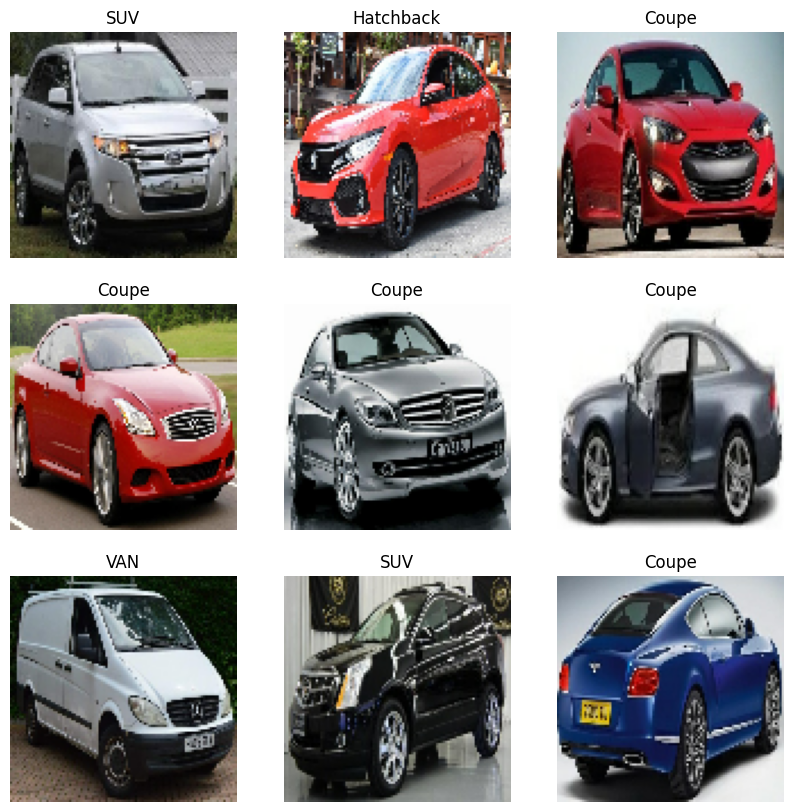

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 10))

for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))

        label_index = np.argmax(labels[i].numpy())
        plt.title(class_names[label_index])

        plt.axis("off")

plt.show()

In [ ]:
for images, labels in test_ds.take(1):
    print("Shape of a batch of images from test_ds:", images.shape)
    print("Shape of a batch of labels from test_ds:", labels.shape)
    break

Shape of a batch of images from test_ds: (32, 100, 100, 3)
Shape of a batch of labels from test_ds: (32, 7)


In [ ]:
def normalize_img(image, label):
  return tf.cast(image, tf.float32) / 255.0, label

train_ds = train_ds.map(normalize_img)
test_ds = test_ds.map(normalize_img)
val_ds = val_ds.map(normalize_img)

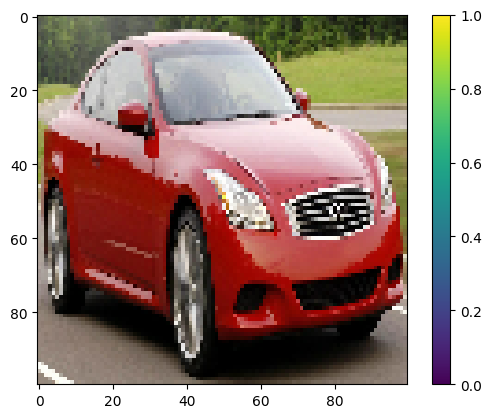

In [ ]:
plt.figure()

# Get one batch from the dataset
for images, labels in train_ds.take(1):
    # Display the first image from the batch
    plt.imshow(images[0].numpy())
    break # We only need one batch

plt.colorbar()
plt.show()

In [ ]:
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(100, 100,3)), # add more hidden layers
    tf.keras.layers.Dense(200, activation='relu'),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(7)
])

In [ ]:
model.compile(
    optimizer='adam',
    loss=tf.keras.losses.CategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

In [ ]:
model.fit(train_ds, epochs=30, batch_size=32)

Epoch 1/30
168/168 ━━━━━━━━━━━━━━━━━━━━ 35s 190ms/step - accuracy: 0.2613 - loss: 2.5576
Epoch 2/30
168/168 ━━━━━━━━━━━━━━━━━━━━ 40s 190ms/step - accuracy: 0.4009 - loss: 1.5897
Epoch 3/30
168/168 ━━━━━━━━━━━━━━━━━━━━ 40s 185ms/step - accuracy: 0.4482 - loss: 1.4927
Epoch 4/30
168/168 ━━━━━━━━━━━━━━━━━━━━ 32s 187ms/step - accuracy: 0.4970 - loss: 1.3725
Epoch 5/30
168/168 ━━━━━━━━━━━━━━━━━━━━ 32s 189ms/step - accuracy: 0.4877 - loss: 1.3700
Epoch 6/30
168/168 ━━━━━━━━━━━━━━━━━━━━ 31s 186ms/step - accuracy: 0.5299 - loss: 1.2567
Epoch 7/30
168/168 ━━━━━━━━━━━━━━━━━━━━ 41s 188ms/step - accuracy: 0.5564 - loss: 1.2032
Epoch 8/30
168/168 ━━━━━━━━━━━━━━━━━━━━ 31s 186ms/step - accuracy: 0.5987 - loss: 1.1050
Epoch 9/30
168/168 ━━━━━━━━━━━━━━━━━━━━ 31s 185ms/step - accuracy: 0.6101 - loss: 1.0638
Epoch 10/30
168/168 ━━━━━━━━━━━━━━━━━━━━ 31s 186ms/step - accuracy: 0.6398 - loss: 0.9869
Epoch 11/30
168/168 ━━━━━━━━━━━━━━━━━━━━ 41s 187ms/step - accuracy: 0.6721 - loss: 0.9393
Epoch 12/30
168/168

In [ ]:
test_loss, test_acc = model.evaluate(test_ds)

print("Test accuracy:", test_acc)
print("Test loss:", test_loss)

26/26 ━━━━━━━━━━━━━━━━━━━━ 3s 121ms/step - accuracy: 0.4900 - loss: 2.3743
Test accuracy: 0.4900249242782593
Test loss: 2.3743326663970947


CNN


In [ ]:
import tensorflow as tf

from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt

In [ ]:
import numpy as np

train_images, train_labels = zip(*[(images.numpy(), labels.numpy()) for images, labels in train_ds])
val_images, val_labels = zip(*[(images.numpy(), labels.numpy()) for images, labels in val_ds])
test_images, test_labels = zip(*[(images.numpy(), labels.numpy()) for images, labels in test_ds])

train_images = np.concatenate(train_images, axis=0)
train_labels = np.concatenate(train_labels, axis=0)

val_images = np.concatenate(val_images, axis=0)
val_labels = np.concatenate(val_labels, axis=0)

test_images = np.concatenate(test_images, axis=0)
test_labels = np.concatenate(test_labels, axis=0)

In [ ]:
print(train_images.shape)
print(train_labels.shape)
print(val_images.shape)
print(val_labels.shape)
print(test_images.shape)
print(test_labels.shape)

(5350, 100, 100, 3)
(5350, 7)
(1397, 100, 100, 3)
(1397, 7)
(802, 100, 100, 3)
(802, 7)


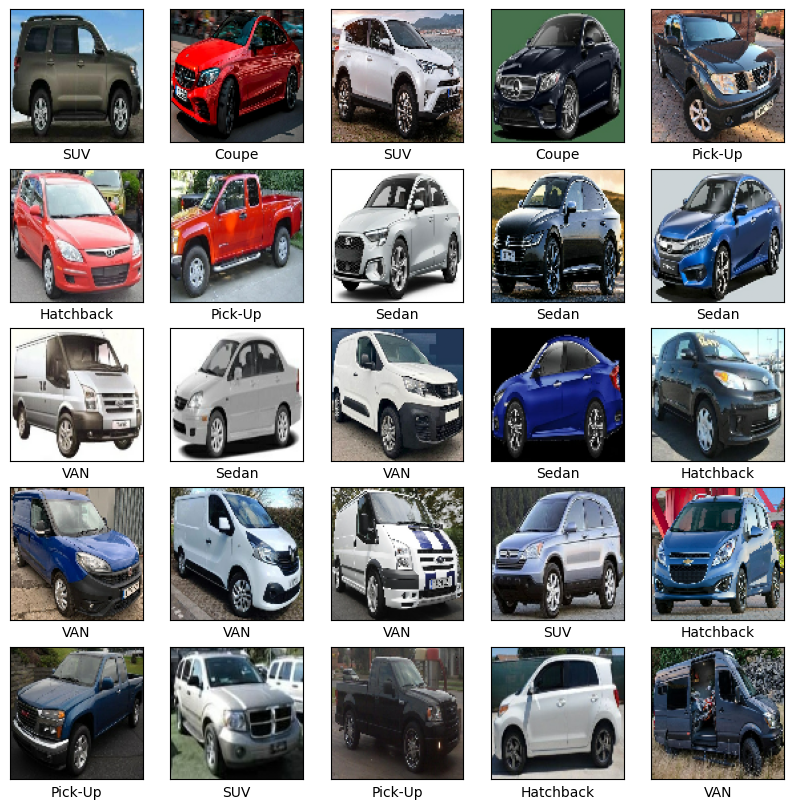

In [ ]:
class_names = ['Convertible', 'Coupe', 'Hatchback', 'Pick-Up', 'SUV', 'Sedan', 'VAN']

plt.figure(figsize=(10, 10))

for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)

    plt.imshow(train_images[i])

    label_index = np.argmax(train_labels[i])
    plt.xlabel(class_names[label_index])

plt.show()

In [ ]:
model = models.Sequential()
model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(100, 100, 3)))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))

In [ ]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 98, 98, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 49, 49, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 47, 47, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 23, 23, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 21, 21, 64)     │        36,928 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,320 (220.00 KB)

 Trainable params: 56,320 (220.00 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.add(layers.Flatten())
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(7))

In [ ]:
model.compile(optimizer='adam',
              loss=tf.keras.losses.CategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

CNN = model.fit(train_images, train_labels, epochs=10,
                    validation_data=(test_images, test_labels)) # fitting model

Epoch 1/10
168/168 ━━━━━━━━━━━━━━━━━━━━ 105s 600ms/step - accuracy: 0.3725 - loss: 1.5774 - val_accuracy: 0.5050 - val_loss: 1.2413
Epoch 2/10
168/168 ━━━━━━━━━━━━━━━━━━━━ 143s 610ms/step - accuracy: 0.6084 - loss: 1.0326 - val_accuracy: 0.5112 - val_loss: 1.2037
Epoch 3/10
168/168 ━━━━━━━━━━━━━━━━━━━━ 94s 560ms/step - accuracy: 0.7050 - loss: 0.7827 - val_accuracy: 0.6721 - val_loss: 0.8874
Epoch 4/10
168/168 ━━━━━━━━━━━━━━━━━━━━ 98s 584ms/step - accuracy: 0.7948 - loss: 0.5640 - val_accuracy: 0.7145 - val_loss: 0.8118
Epoch 5/10
168/168 ━━━━━━━━━━━━━━━━━━━━ 99s 589ms/step - accuracy: 0.8636 - loss: 0.3794 - val_accuracy: 0.7132 - val_loss: 0.8343
Epoch 6/10
168/168 ━━━━━━━━━━━━━━━━━━━━ 146s 608ms/step - accuracy: 0.9164 - loss: 0.2379 - val_accuracy: 0.7369 - val_loss: 0.8812
Epoch 7/10
168/168 ━━━━━━━━━━━━━━━━━━━━ 103s 611ms/step - accuracy: 0.9557 - loss: 0.1322 - val_accuracy: 0.7519 - val_loss: 0.9797
Epoch 8/10
168/168 ━━━━━━━━━━━━━━━━━━━━ 138s 588ms/step - accuracy: 0.9701 - lo

In [ ]:
test_loss, test_acc = model.evaluate(test_images,  test_labels)

print('\nTest accuracy:', test_acc)

26/26 ━━━━━━━━━━━━━━━━━━━━ 3s 127ms/step - accuracy: 0.7519 - loss: 1.4687

Test accuracy: 0.751870334148407


26/26 - 5s - 193ms/step - accuracy: 0.7519 - loss: 1.4687


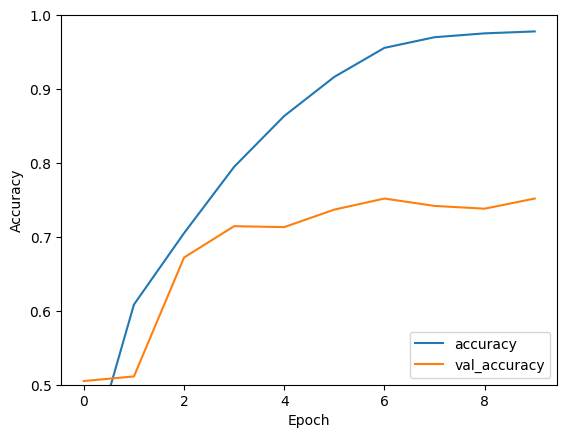

In [ ]:
plt.plot(CNN.history['accuracy'], label='accuracy')
plt.plot(CNN.history['val_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0.5, 1])
plt.legend(loc='lower right')

test_loss, test_acc = model.evaluate(test_images,  test_labels, verbose=2)